In [ ]:
# UAV Computer Vision Project

## Dataset Exploration (EDA)

**Dataset:** VisDrone-2019 DET

### Objectives

- Explore the dataset structure
- Analyze image statistics
- Analyze annotations
- Study class distribution
- Visualize bounding boxes
- Identify potential data quality issues

In [1]:
import os
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

plt.style.use("ggplot")

In [2]:
from pathlib import Path

BASE_PATH = Path(r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\VisDrone-2019-DET")

TRAIN_IMAGES = Path(r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\VisDrone-2019-DET\VisDrone2019-DET-train\VisDrone2019-DET-train\images")
TRAIN_LABELS = Path(r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\VisDrone-2019-DET\VisDrone2019-DET-train\VisDrone2019-DET-train\annotations")

VAL_IMAGES = Path(r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\VisDrone-2019-DET\VisDrone2019-DET-val\VisDrone2019-DET-val\images")
VAL_LABELS = Path(r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\VisDrone-2019-DET\VisDrone2019-DET-val\VisDrone2019-DET-val\annotations")

In [3]:
print("Training Images Exists :", TRAIN_IMAGES.exists())
print("Training Labels Exists :", TRAIN_LABELS.exists())

print("Validation Images Exists :", VAL_IMAGES.exists())
print("Validation Labels Exists :", VAL_LABELS.exists())

Training Images Exists : True
Training Labels Exists : True
Validation Images Exists : True
Validation Labels Exists : True


In [15]:
train_images = list(TRAIN_IMAGES.glob("*.jpg"))
val_images = list(VAL_IMAGES.glob("*.jpg"))

print(f"Training Images : {len(train_images)}")
print(f"Validation Images : {len(val_images)}")


Training Images : 6471
Validation Images : 548


In [6]:
missing_annotations = []

for image in train_images:
    annotation = TRAIN_LABELS / f"{image.stem}.txt"

    if not annotation.exists():
        missing_annotations.append(image.name)

print(f"Missing Annotation Files : {len(missing_annotations)}")

Missing Annotation Files : 0


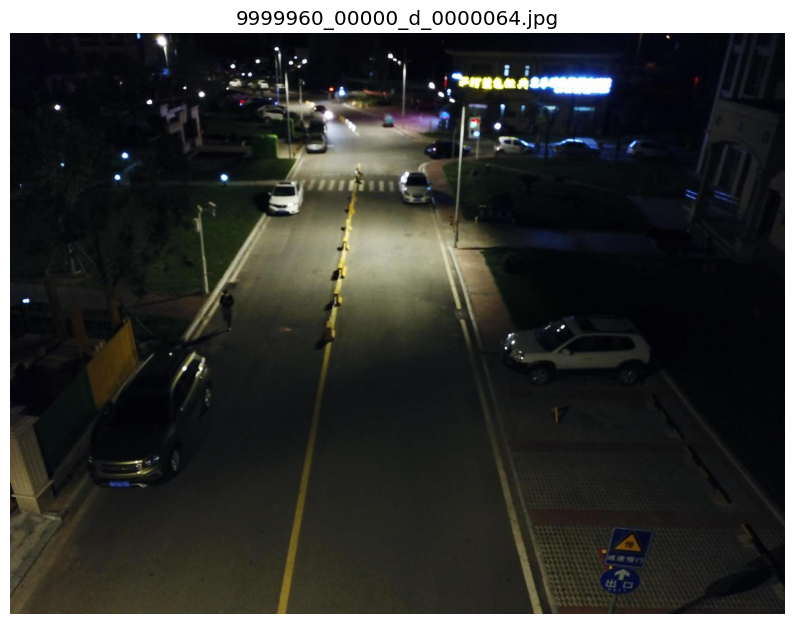

In [7]:
# Display a random training image

random_image = random.choice(train_images)

image = cv2.imread(str(random_image))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,8))
plt.imshow(image)
plt.title(random_image.name)
plt.axis("off")

plt.show()

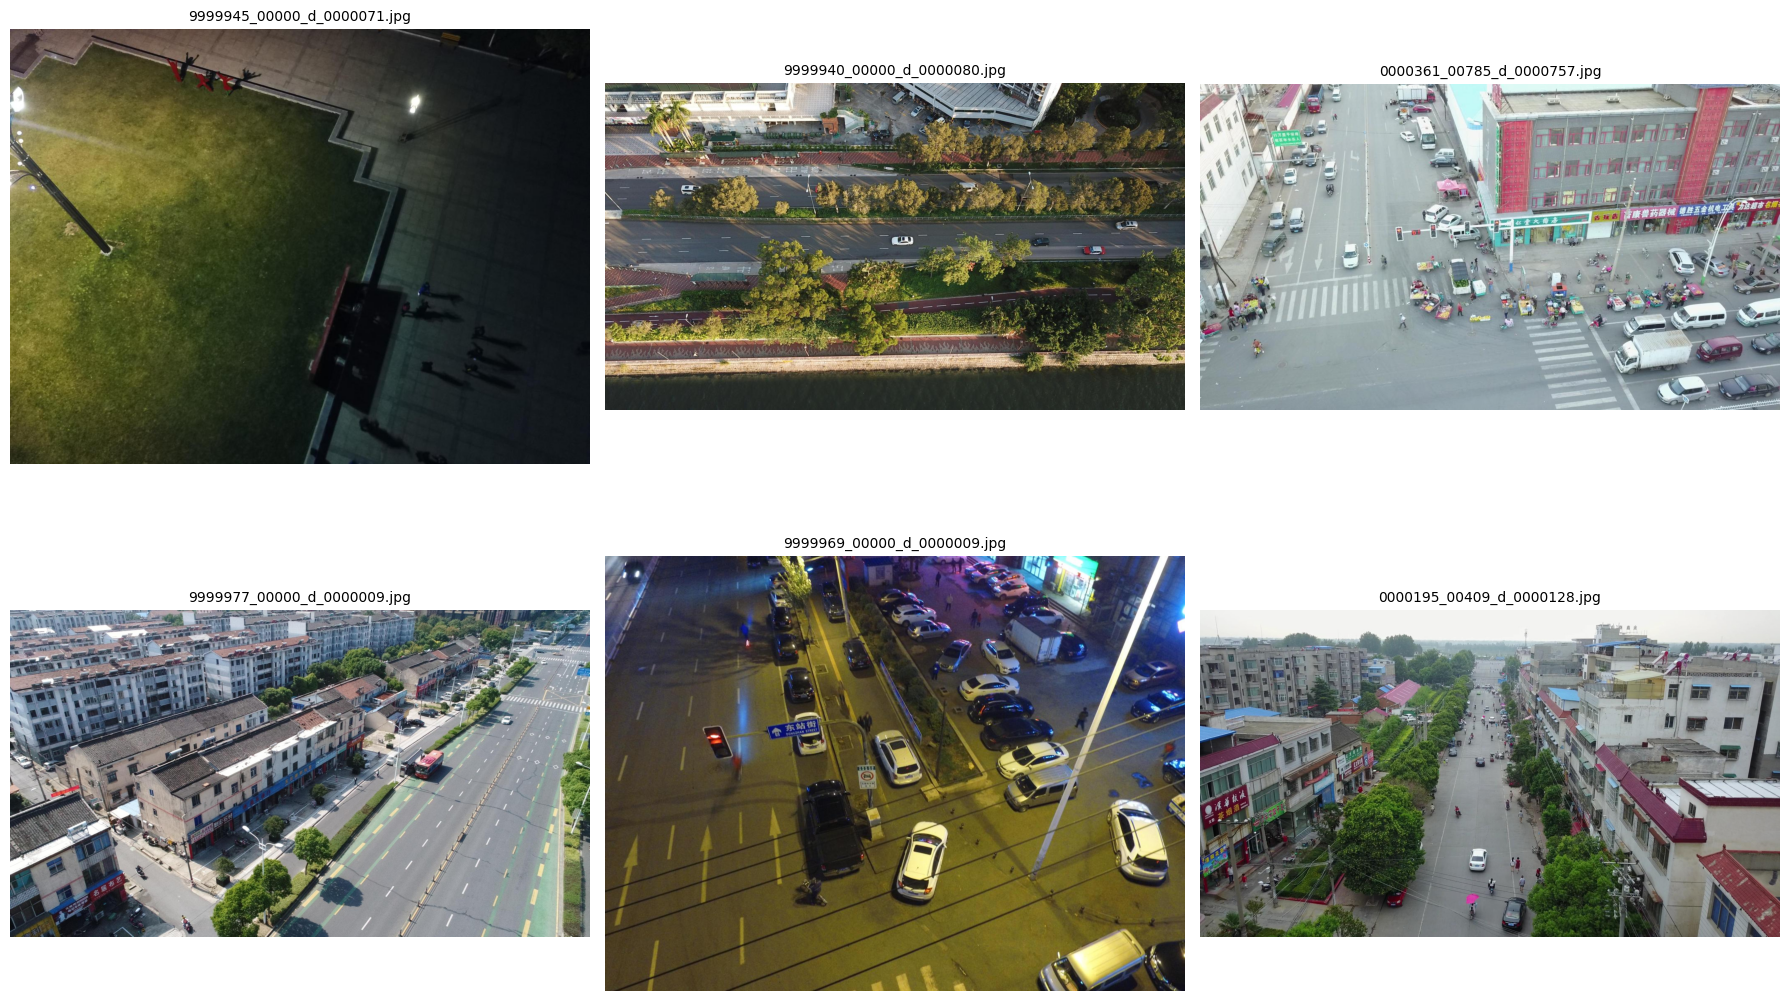

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax in axes.ravel():

    img_path = random.choice(train_images)

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
image_heights = []
image_widths = []

for img_path in train_images:

    img = cv2.imread(str(img_path))

    h, w = img.shape[:2]

    image_heights.append(h)
    image_widths.append(w)

print(f"Minimum Height : {min(image_heights)}")
print(f"Maximum Height : {max(image_heights)}")

print(f"Minimum Width : {min(image_widths)}")
print(f"Maximum Width : {max(image_widths)}")

Minimum Height : 360
Maximum Height : 1500
Minimum Width : 480
Maximum Width : 2000


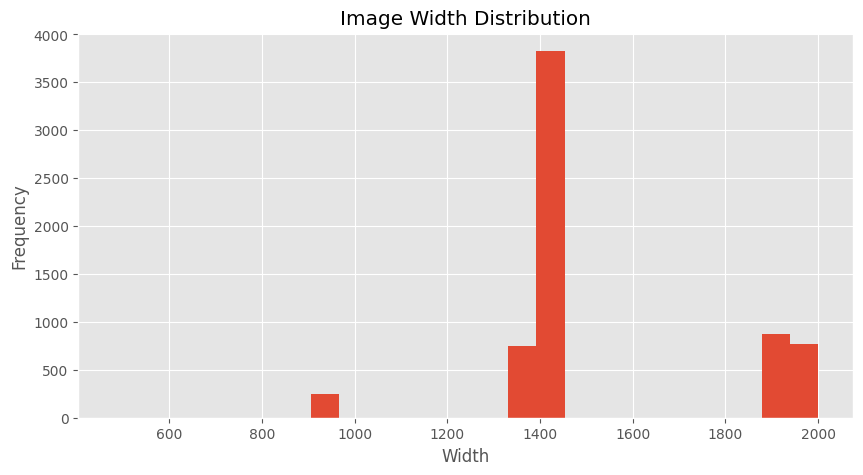

In [10]:
plt.figure(figsize=(10,5))

plt.hist(image_widths, bins=25)

plt.title("Image Width Distribution")
plt.xlabel("Width")
plt.ylabel("Frequency")

plt.show()

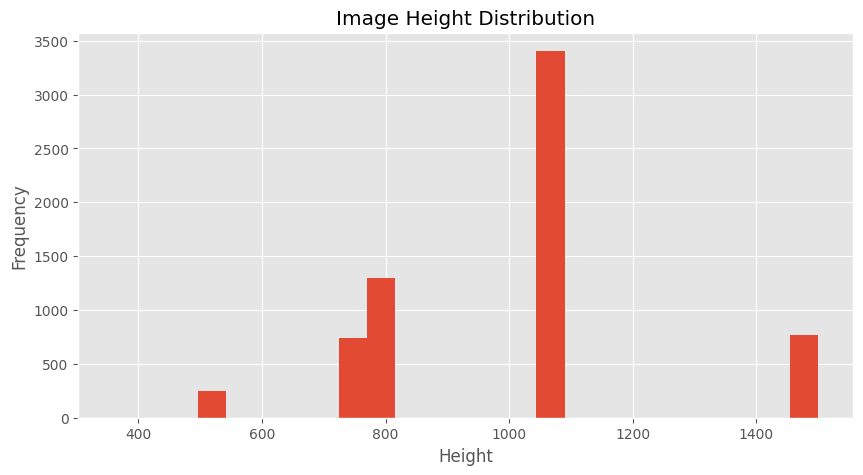

In [11]:
plt.figure(figsize=(10,5))

plt.hist(image_heights, bins=25)

plt.title("Image Height Distribution")
plt.xlabel("Height")
plt.ylabel("Frequency")

plt.show()

In [ ]:
## Dataset Observations

- Images captured from UAVs at varying altitudes and camera angles.
- Contains both day and night scenes.
- Includes urban roads, highways, parking lots, and residential areas.
- Significant variation in image resolution.
- Many objects are very small, making detection challenging.
- Crowded scenes suggest that accurate localization will be important.

In [16]:
train_labels = list(TRAIN_LABELS.glob("*.txt"))
val_labels = list(VAL_LABELS.glob("*.txt"))

print(f"Training Labels : {len(train_labels)}")
print(f"Validation Labels : {len(val_labels)}")

Training Labels : 6471
Validation Labels : 548


In [17]:
# Select a random annotation file
random_label = random.choice(train_labels)

print("Annotation File:", random_label.name)

# Read and print its contents
with open(random_label, "r") as f:
    lines = f.readlines()

for line in lines[:10]:
    print(line.strip())

Annotation File: 9999943_00000_d_0000044.txt
333,458,13,29,1,1,0,0
156,385,238,199,1,6,0,1
0,306,62,62,1,4,1,1
185,201,70,53,1,4,0,1
810,1008,17,31,1,1,0,0
456,818,18,33,1,1,0,0
408,711,17,26,1,1,0,0
396,692,16,35,1,1,0,0
623,491,94,73,1,4,0,0
463,353,75,53,1,4,0,0


In [18]:
VISDRONE_CLASSES = {
    0: "Ignored",
    1: "Pedestrian",
    2: "People",
    3: "Bicycle",
    4: "Car",
    5: "Van",
    6: "Truck",
    7: "Tricycle",
    8: "Awning Tricycle",
    9: "Bus",
    10: "Motor"
}

In [19]:
print(f"Objects in {random_label.name}: {len(lines)}")

Objects in 9999943_00000_d_0000044.txt: 71


In [20]:
# Select a random image
image_path = random.choice(train_images)

# Find its annotation file
label_path = TRAIN_LABELS / f"{image_path.stem}.txt"

print(image_path.name)
print(label_path.name)

0000228_01419_d_0000004.jpg
0000228_01419_d_0000004.txt


In [21]:
VISDRONE_CLASSES = {
    0: "Ignored",
    1: "Pedestrian",
    2: "People",
    3: "Bicycle",
    4: "Car",
    5: "Van",
    6: "Truck",
    7: "Tricycle",
    8: "Awning Tricycle",
    9: "Bus",
    10: "Motor"
}

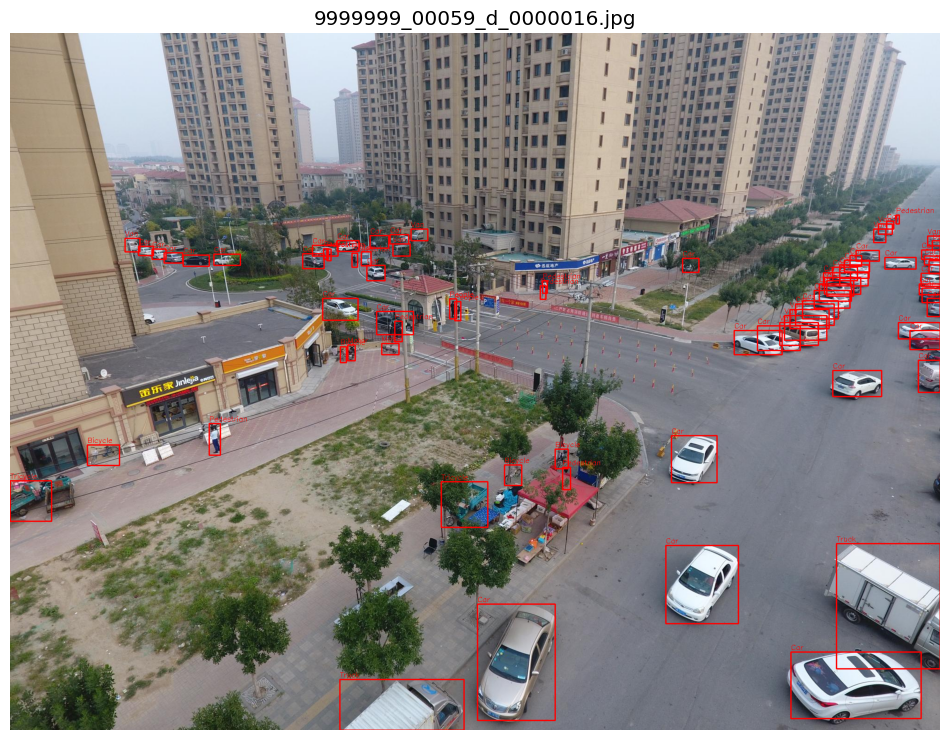

In [22]:
# Select a random image
image_path = random.choice(train_images)

# Find the corresponding annotation file
label_path = TRAIN_LABELS / f"{image_path.stem}.txt"

# Read image
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Read annotation file
with open(label_path, "r") as f:
    annotations = f.readlines()

# Draw bounding boxes
for annotation in annotations:

    values = annotation.strip().split(",")

    x = int(values[0])
    y = int(values[1])
    w = int(values[2])
    h = int(values[3])

    score = int(values[4])
    class_id = int(values[5])

    # Skip ignored objects
    if score == 0:
        continue

    class_name = VISDRONE_CLASSES.get(class_id, "Unknown")

    # Draw rectangle
    cv2.rectangle(
        image,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

    # Draw class label
    cv2.putText(
        image,
        class_name,
        (x, y - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(12,10))
plt.imshow(image)
plt.axis("off")
plt.title(image_path.name)

plt.show()

In [23]:
from collections import Counter

# Dictionary to store class counts
class_counter = Counter()

# Read every annotation file
for label_file in train_labels:

    with open(label_file, "r") as f:
        annotations = f.readlines()

    for annotation in annotations:

        values = annotation.strip().split(",")

        score = int(values[4])
        class_id = int(values[5])

        # Skip ignored objects
        if score == 0:
            continue

        class_counter[class_id] += 1

In [24]:
class_df = pd.DataFrame({
    "Class ID": class_counter.keys(),
    "Count": class_counter.values()
})

# Map IDs to names
class_df["Class Name"] = class_df["Class ID"].map(VISDRONE_CLASSES)

# Sort by Class ID
class_df = class_df.sort_values("Class ID")

class_df

,Class ID,Count,Class Name
8,1,79337,Pedestrian
1,2,27059,People
5,3,10480,Bicycle
0,4,144867,Car
2,5,24956,Van
3,6,12875,Truck
6,7,4812,Tricycle
7,8,3246,Awning Tricycle
9,9,5926,Bus
4,10,29647,Motor


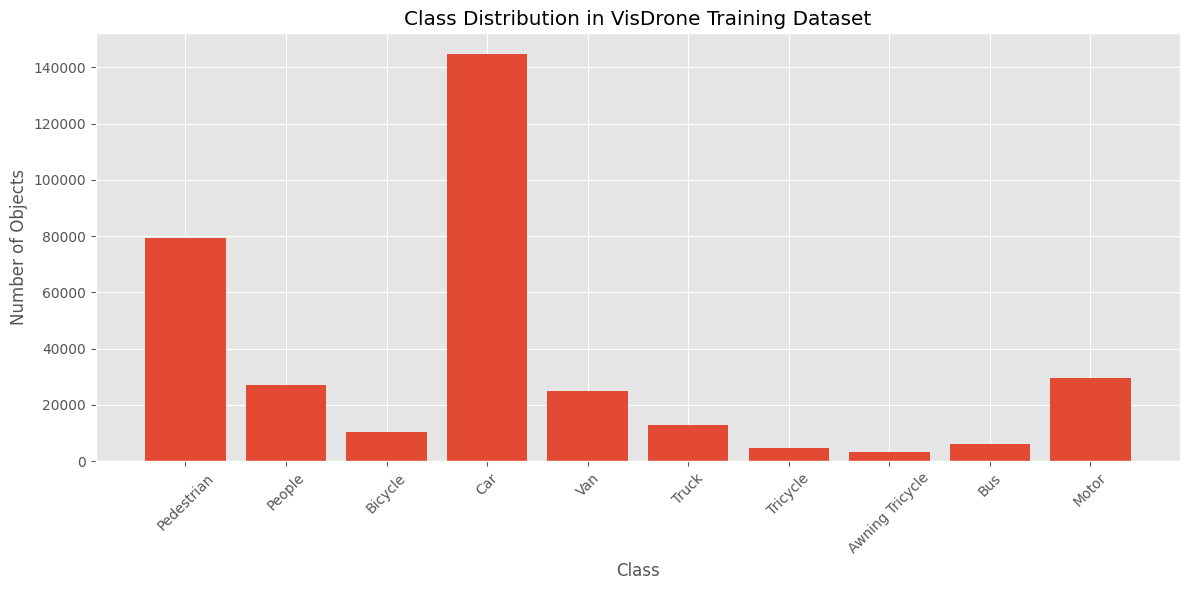

In [25]:
plt.figure(figsize=(12,6))

plt.bar(class_df["Class Name"], class_df["Count"])

plt.xticks(rotation=45)
plt.xlabel("Class")
plt.ylabel("Number of Objects")
plt.title("Class Distribution in VisDrone Training Dataset")

plt.tight_layout()
plt.show()

In [26]:
print("Most Frequent Class:")
print(class_df.loc[class_df["Count"].idxmax()])

print("\nLeast Frequent Class:")
print(class_df.loc[class_df["Count"].idxmin()])

Most Frequent Class:
Class ID           4
Count         144867
Class Name       Car
Name: 0, dtype: object

Least Frequent Class:
Class ID                    8
Count                    3246
Class Name    Awning Tricycle
Name: 7, dtype: object


In [ ]:
## Class Distribution Analysis

### Observations

- The dataset is highly imbalanced.
- Cars are the dominant object class with 144,867 instances.
- Pedestrians are the second most frequent class.
- Awning Tricycle is the least represented class.
- The dataset reflects realistic urban traffic conditions.
- Small classes may require additional augmentation or careful evaluation.

In [27]:
box_areas = []

for label_file in train_labels:

    with open(label_file, "r") as f:
        annotations = f.readlines()

    for annotation in annotations:

        values = annotation.strip().split(",")

        score = int(values[4])

        if score == 0:
            continue

        width = int(values[2])
        height = int(values[3])

        area = width * height

        box_areas.append(area)

In [28]:
box_df = pd.DataFrame(box_areas, columns=["Area"])

box_df.describe()

,Area
count,343205.000000
mean,2448.398604
std,6598.458460
min,0.000000
25%,243.000000
50%,680.000000
75%,2025.000000
max,328640.000000


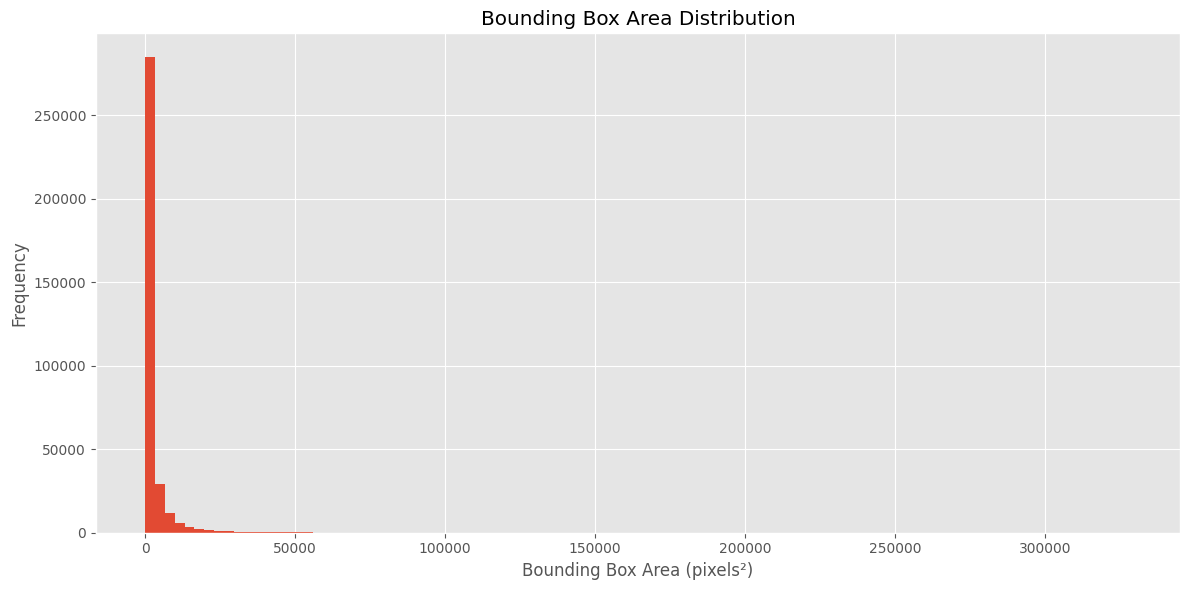

In [29]:
plt.figure(figsize=(12,6))

plt.hist(box_areas, bins=100)

plt.xlabel("Bounding Box Area (pixels²)")
plt.ylabel("Frequency")
plt.title("Bounding Box Area Distribution")

plt.tight_layout()
plt.show()

In [31]:
small = sum(a < 1024 for a in box_areas)
medium = sum(1024 <= a < 9216 for a in box_areas)
large = sum(a >= 9216 for a in box_areas)

print(f"Small Objects : {small}")
print(f"Medium Objects: {medium}")
print(f"Large Objects : {large}")
total = len(box_areas)

print(f"Small Objects : {small} ({small/total*100:.2f}%)")
print(f"Medium Objects: {medium} ({medium/total*100:.2f}%)")
print(f"Large Objects : {large} ({large/total*100:.2f}%)")

Small Objects : 207525
Medium Objects: 116696
Large Objects : 18984
Small Objects : 207525 (60.47%)
Medium Objects: 116696 (34.00%)
Large Objects : 18984 (5.53%)


In [ ]:
## Bounding Box Analysis

### Observations

- The bounding box area distribution is highly right-skewed.
- Most objects occupy a very small area in the image.
- Only a small number of objects have large bounding boxes.
- This confirms that VisDrone is a challenging small-object detection dataset.
- Higher input resolutions may improve detection performance for small objects.


In [ ]:
# Final EDA Summary

## Dataset Quality

- Dataset contains no missing annotation files.
- Images have varying resolutions.
- Images represent diverse UAV environments.

## Class Distribution

- Cars dominate the dataset.
- Awning Tricycle is the least represented class.
- Dataset reflects realistic traffic distributions.

## Object Size Analysis

- Small Objects : 60.47%
- Medium Objects : 34.00%
- Large Objects : 5.53%

The dataset is dominated by small objects, making it a challenging benchmark for UAV object detection. Future model training should consider input resolution and evaluation of small-object performance.